# Laptop Price Category Prediction - Classification Track (Algorithms 1-10)

## Scope of this notebook

This notebook covers ten classification algorithms for the capstone:

1. **Logistic Regression**
2. **K-Nearest Neighbors**
3. **Gaussian Naive Bayes**
4. **Decision Tree Classifier**
5. **Support Vector Classifier (SVC)**
6. **Random Forest Classifier**
7. **AdaBoost Classifier**
8. **Gradient Boosting Classifier**
9. **Bagging Classifier**
10. **MLP Classifier (Neural Network)**

The data used here is classification.csv, produced by the pre_preprocessing notebook. It contains the same cleaned and encoded laptop specs as the other tracks (company, laptop type, OS, RAM, weight, screen size, storage, resolution, PPI, IPS/touchscreen flags, SSD/HDD flags), but instead of the raw price, the target column is price_category - laptops binned into four quartile-based groups: Budget, Mid-range, Premium, and Flagship. price itself was dropped when this file was built, since keeping it alongside a category derived directly from it would let the model see the answer.


## 1. Load classification.csv

classification.csv is read in and head() is checked just to confirm the columns loaded correctly - one-hot encoded company/type/OS columns, the numeric spec columns, the boolean flags, and price_category as the last column.


In [1]:
# Load the dataset

import pandas as pd
df = pd.read_csv('data/classification.csv')
df.head()

,inches,ram,weight,is_ips,is_touchscreen,res_width,res_height,storage_gb,has_ssd,has_hdd,...,typename_Workstation,opsys_Chrome Os,opsys_Linux,opsys_Mac Os X,opsys_Macos,opsys_No Os,opsys_Windows 10,opsys_Windows 10 S,opsys_Windows 7,price_category
0,13.3,8.0,1.37,1,0,2560,1600,128.0,1,0,...,False,False,False,False,True,False,False,False,False,Premium
1,13.3,8.0,1.34,0,0,1440,900,128.0,0,0,...,False,False,False,False,True,False,False,False,False,Mid-range
2,15.6,8.0,1.86,0,0,1920,1080,256.0,1,0,...,False,False,False,False,False,True,False,False,False,Budget
3,15.4,16.0,1.83,1,0,2880,1800,512.0,1,0,...,False,False,False,False,True,False,False,False,False,Flagship
4,13.3,8.0,1.37,1,0,2560,1600,256.0,1,0,...,False,False,False,False,True,False,False,False,False,Flagship


## 2. Split into features and target

price_category is pulled out as y and everything else becomes X. The value counts show how the four price bands are distributed across the dataset - since price_category was built from quartiles of price, the four classes should be close to equal in size to begin with, but the exact counts are worth checking since the cleaning steps upstream (dropping missing rows, removing duplicates) could have shifted the balance slightly.


In [2]:
# Separate features and target

X = df.drop('price_category', axis=1)
y = df['price_category']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts())

Features shape: (1243, 42)
Target shape: (1243,)

Class distribution:
price_category
Mid-range    312
Budget       311
Flagship     311
Premium      309
Name: count, dtype: int64


## 3. Class distribution plot

Plotting the counts as a bar chart just makes the balance (or imbalance) easier to see at a glance than reading numbers off a printout. If the bars come out roughly the same height, that's a sign the quartile-based binning did its job.


price_category
Mid-range    312
Budget       311
Flagship     311
Premium      309
Name: count, dtype: int64


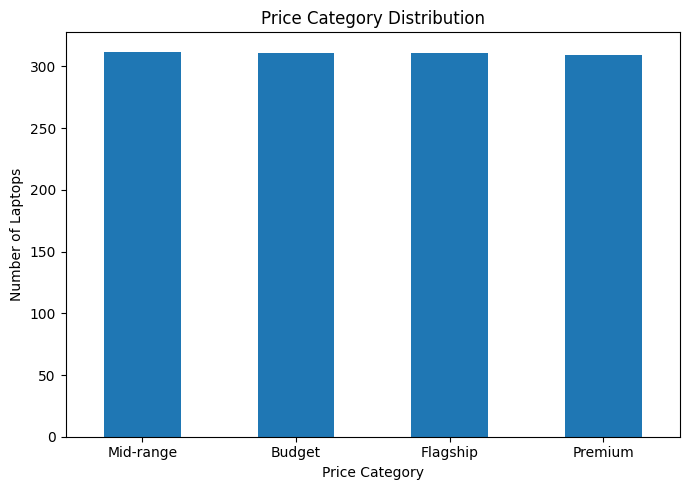

In [3]:
# Check Target distribution

import matplotlib.pyplot as plt

print(y.value_counts())

plt.figure(figsize=(7, 5))
y.value_counts().plot(kind='bar')

plt.title('Price Category Distribution')
plt.xlabel('Price Category')
plt.ylabel('Number of Laptops')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

A few things worth noting from this chart when writing it up: which category has the most/fewest laptops, and how big the gap is between the largest and smallest bar. Even a small imbalance is the reason accuracy alone isn't reported later - weighted F1 is used alongside it so a class with slightly fewer samples doesn't get ignored in the scoring.


## 4. Train/test split

An 80:20 split, stratified on y so all four price categories show up in roughly the same proportion in both the training and test sets. Since price_category is already a discrete label, stratifying is straightforward here.


In [4]:
# Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (994, 42)
Testing set: (249, 42)


## 5. Scaling

StandardScaler is fit only on the training data and then applied to both train and test, so nothing from the test set leaks into the scaling statistics.

Logistic Regression, KNN, and SVC all use the scaled versions below, since they're either distance-based or rely on gradient optimisation that behaves badly when features like ram and res_width sit on very different numeric scales. The Decision Tree later in the notebook is fit on the unscaled data instead - it splits on thresholds per feature, so scaling makes no difference to how it partitions the data.


In [5]:
# Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


<h1 style="font-size:22pt">1) Logistic Regression</h1>


Logistic Regression is used here as the baseline model. It fits a linear decision boundary between the four price categories on the standardised features and converts that into class probabilities. max_iter is bumped up to 1000 so the solver has enough room to converge given the number of encoded features.


In [6]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

y_pred_logistic = logistic_model.predict(X_test_scaled)

print("Logistic Regression completed.")

Logistic Regression completed.


In [ ]:
# Coefficients and odds ratios

import numpy as np

coef_df = pd.DataFrame(
    logistic_model.coef_,
    columns=X_train.columns,
    index=logistic_model.classes_
)

odds_df = np.exp(coef_df)

print("Logistic Regression classes:", logistic_model.classes_.tolist())
print("\nMost negative coefficients for Premium (push away from Premium):")
print(coef_df.loc['Premium'].sort_values().head(5))
print("\nMost positive coefficients for Premium (push toward Premium):")
print(coef_df.loc['Premium'].sort_values().tail(5))

Logistic Regression is fit with one set of coefficients per class, since price_category has four classes, so each class gets its own view of which features push a laptop toward it. Taking Premium as an example, ram, has_ssd, ppi, has_hdd, and company_Dell have the largest positive coefficients, meaning higher values on those (or belonging to that company) push the predicted probability of Premium up. is_touchscreen, typename_Notebook, weight, and storage_gb have the most negative coefficients for Premium, meaning laptops with those traits are pushed away from being classified Premium.

Exponentiating a coefficient turns it into an odds ratio: exp(coefficient) is how much the odds of that class multiply by for a one standard deviation increase in the feature, since the inputs were standardised before fitting. An odds ratio above 1 means the feature increases the odds of that class, and below 1 means it decreases them. This is the same coefficients-to-odds step used to explain any logistic regression, just repeated once per class here because of the multi-class target.


<h1 style="font-size:22pt">2) K-Nearest Neighbors</h1>

KNN predicts a laptop's price category by looking at its closest neighbours in the scaled feature space and taking a majority vote. GridSearchCV is used to pick the best n_neighbors from [3, 5, 7, 9, 11, 13, 15], and this search also tunes the distance metric itself over euclidean, manhattan, and minkowski, using 5-fold CV scored on weighted F1 rather than accuracy, to keep the class imbalance in mind while tuning.

The choice of metric changes what "closest" even means. Euclidean distance is straight-line distance and treats every feature direction the same way. Manhattan distance adds up the absolute difference along each feature axis instead of taking a straight line, which can behave better when a lot of features are the binary one-hot columns in this dataset, since a straight-line distance across many 0/1 dimensions does not always match how different two laptops really are. Minkowski is the general form that includes both Euclidean and Manhattan as special cases, controlled by a power parameter. Letting the grid search choose between them, rather than assuming Euclidean by default, is what the metric parameter in the grid is doing here.


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

knn_param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 13, 15],
    'metric': ['euclidean', 'manhattan', 'minkowski']
}

knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    knn_param_grid,
    cv=5,
    scoring='f1_weighted'
)

knn_grid.fit(X_train_scaled, y_train)

print("Best KNN parameters:", knn_grid.best_params_)

In [8]:
# best KNN model

knn_model = knn_grid.best_estimator_

y_pred_knn = knn_model.predict(X_test_scaled)

print("KNN completed.")

KNN completed.


A small k lets the boundary follow local structure closely but can be thrown off by individual noisy points near the border between two price bands. A larger k smooths things out but risks blending together laptops from neighbouring categories (say, Mid-range and Premium) that are genuinely close in spec but priced differently. Whatever value the grid search picks reflects where that trade-off worked best on the training folds.


<h1 style="font-size:22pt">3) Gaussian Naive Bayes</h1>


Naive Bayes assumes each feature is independent given the price category and models each one as a Gaussian within that category. There's no hyperparameter search for this one - it's fit directly, which also makes it by far the quickest model to train.

The independence assumption is a stretch for this dataset though - features like ram, storage_gb, and res_width tend to move together (higher-spec laptops are higher-spec across the board), so this is really here as a simple, fast baseline rather than a model expected to lead the comparison.


In [9]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(X_train_scaled, y_train)

y_pred_nb = nb_model.predict(X_test_scaled)

print("Gaussian Naive Bayes completed.")

Gaussian Naive Bayes completed.


<h1 style="font-size:22pt">4) Decision Tree Classifier</h1>


The tree splits on individual feature thresholds (e.g. ram <= 8), which is why it's trained on the unscaled X_train/X_test rather than the scaled versions used above. GridSearchCV searches max_depth over [2, 3, 4, 5, 6, 8, 10, None] with 5-fold CV on weighted F1 - depth is capped this way because an unrestricted tree (max_depth=None) will keep splitting until it fits the training data almost perfectly, which usually means it's memorising noise rather than learning anything that generalises.


In [10]:
from sklearn.tree import DecisionTreeClassifier

dt_param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 8, 10, None]
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_param_grid,
    cv=5,
    scoring='f1_weighted'
)

dt_grid.fit(X_train, y_train)

print("Best Decision Tree parameters:", dt_grid.best_params_)

Best Decision Tree parameters: {'max_depth': 6}


In [11]:
# best decision tree

dt_model = dt_grid.best_estimator_

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree completed.")

Decision Tree completed.


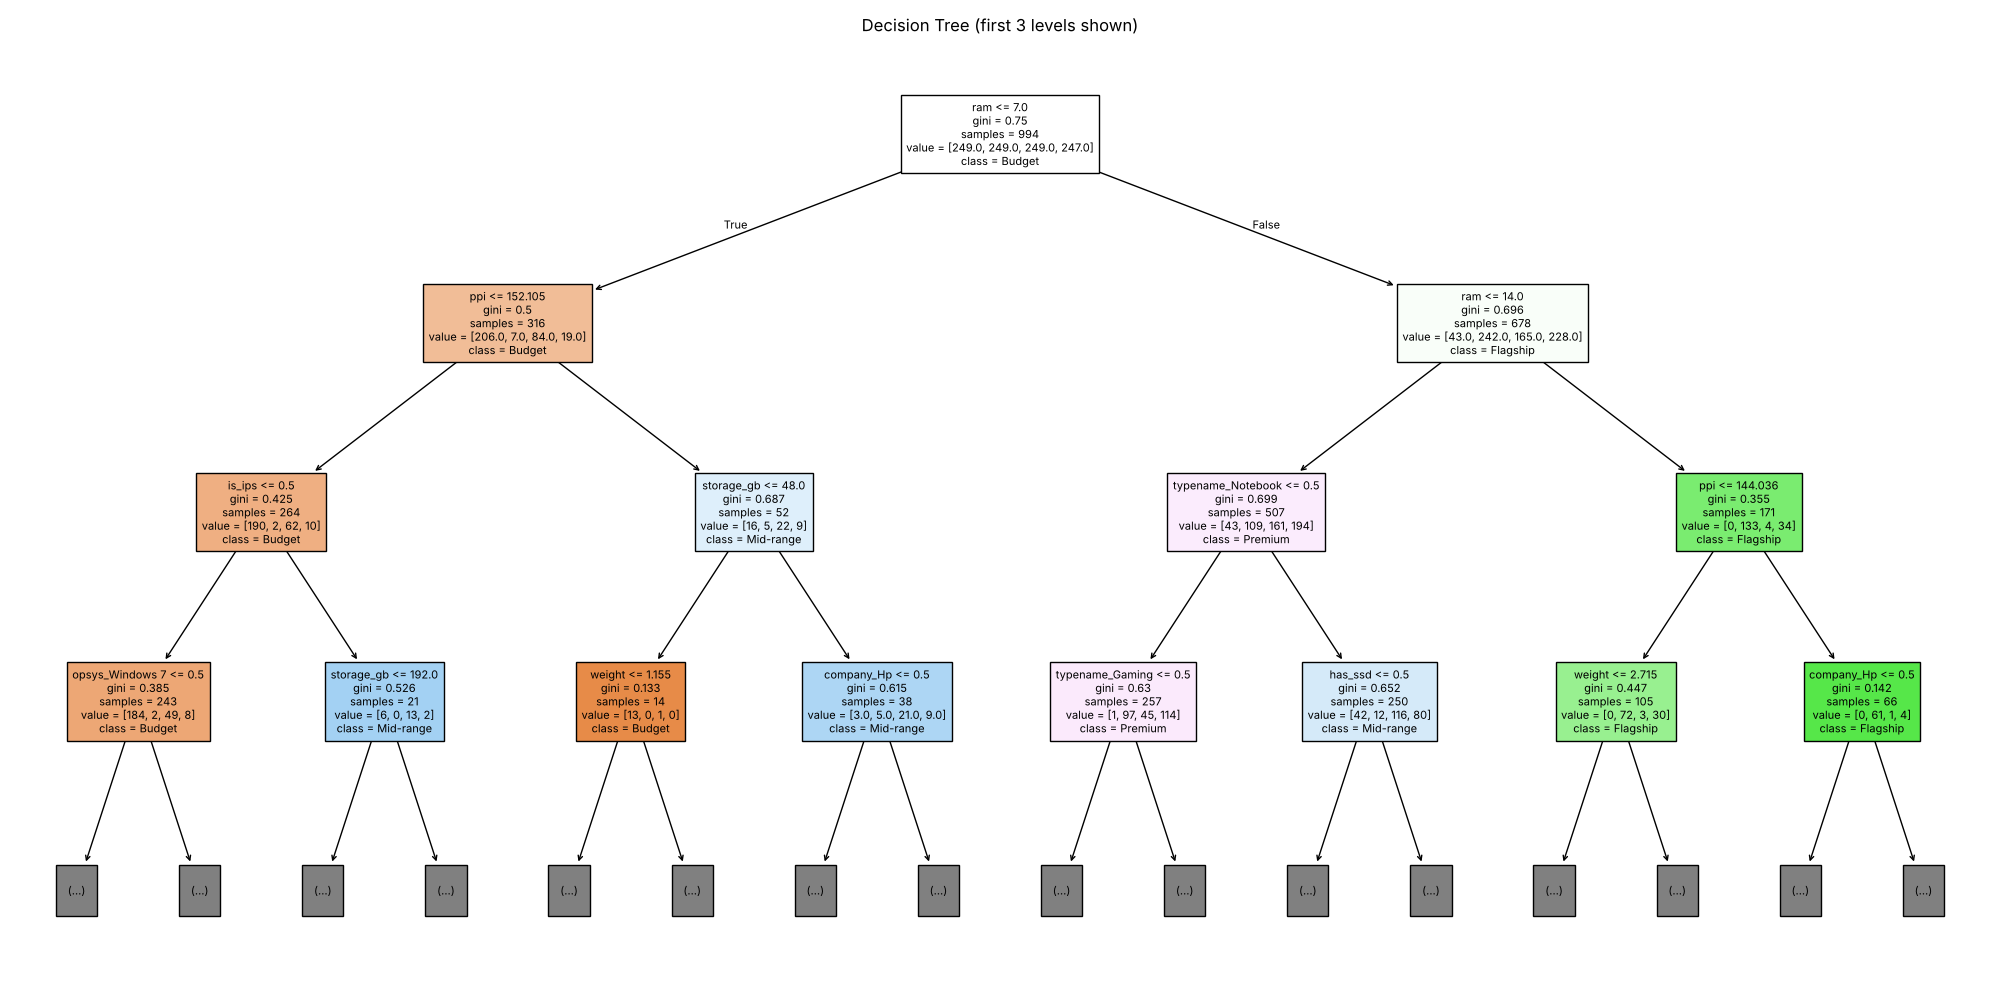

In [1]:
# Visualise the tree (first 3 levels, for legibility)

from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(
    dt_model,
    max_depth=3,
    feature_names=X_train.columns,
    class_names=dt_model.classes_,
    filled=True,
    fontsize=8,
    ax=ax
)
ax.set_title('Decision Tree (first 3 levels shown)')
plt.tight_layout()
plt.show()

Only the first three levels are drawn here since the tree actually fitted goes to max_depth 6 and would be unreadable in full. Each box shows the splitting rule, how many training laptops reach that node, how they break down across the four price categories, and which class the node would predict. The feature chosen at the very top split is the single most useful one for telling the four price bands apart on its own, and the features chosen a level or two down show what matters once that first split has already separated out some of the laptops.


If the search settles on a shallow tree, that suggests a handful of features (probably RAM, storage, and screen specs) do most of the work separating the four price bands. A deeper tree picked by the search would mean the categories overlap more and need extra splits/interactions to pull apart cleanly.


<h1 style="font-size:22pt">5) Support Vector Classifier - SVC</h1>


SVC looks for the boundary that separates the price categories with the widest margin, using the scaled features since the margin calculation is distance-based. The grid search tunes two things together:

- C in [0.1, 1, 10, 100] - how much the model is penalised for training points that fall on the wrong side of the margin; small C favours a wider, more forgiving margin, large C fits the training points more tightly.
- kernel in ['linear', 'rbf', 'poly'] - whether the boundary is a straight hyperplane or allowed to curve.

Both are searched jointly with 5-fold CV, scored on weighted F1.

probability=True is set on the estimator as well, so that it produces class probabilities and not just hard predictions - this is what the ROC-AUC calculation in the evaluation section needs, since ROC-AUC is computed from predicted probabilities rather than predicted labels.


In [ ]:
from sklearn.svm import SVC

svc_param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly']
}

svc_grid = GridSearchCV(
    SVC(random_state=42, probability=True),
    svc_param_grid,
    cv=5,
    scoring='f1_weighted'
)

svc_grid.fit(X_train_scaled, y_train)

print("Best SVC parameters:", svc_grid.best_params_)

In [13]:
# Best SVC

svc_model = svc_grid.best_estimator_

y_pred_svc = svc_model.predict(X_test_scaled)

print("SVC completed.")

SVC completed.


<h1 style="font-size:22pt">6) Random Forest Classifier</h1>


A Random Forest trains a batch of decision trees, each on a bootstrapped sample of the training rows with a random subset of features considered at each split, and then averages their votes. Because it is still an ensemble of trees splitting on thresholds, it is trained on the unscaled X_train and X_test, the same as the single Decision Tree above.

GridSearchCV tunes n_estimators, which is how many trees get built, over 100, 200 and 300, and max_depth over 4, 6, 8, 10 and None, with 5 fold cross validation scored on weighted F1.


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [4, 6, 8, 10, None]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_param_grid,
    cv=5,
    scoring='f1_weighted'
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest parameters:", rf_grid.best_params_)

In [ ]:
# best random forest

rf_model = rf_grid.best_estimator_

y_pred_rf = rf_model.predict(X_test)

print("Random Forest completed.")

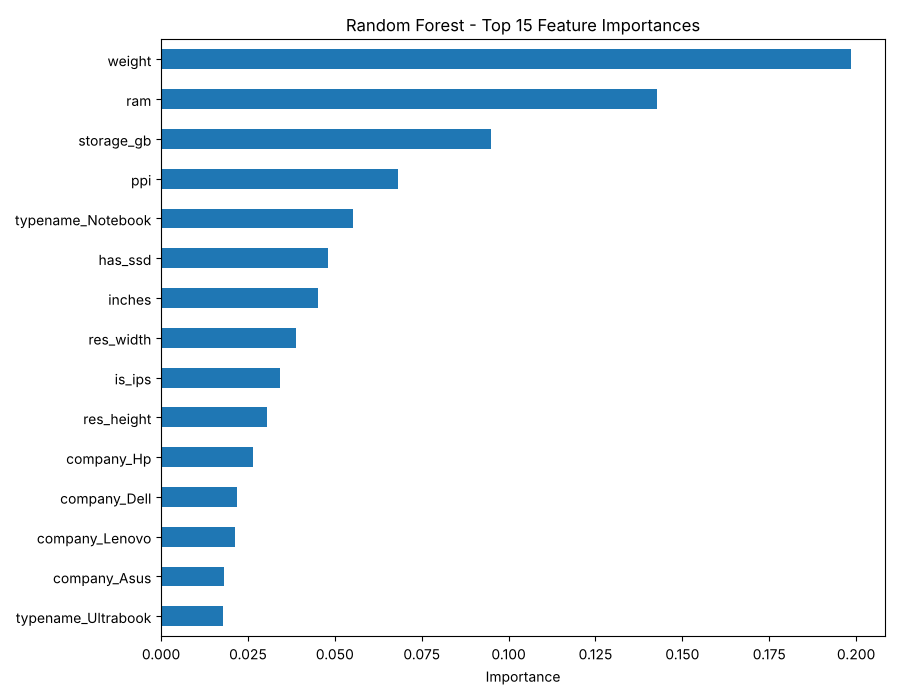

In [1]:
# Feature importance

importances = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

top_importances = importances.head(15)

plt.figure(figsize=(9, 7))
top_importances.sort_values().plot(kind='barh')
plt.title('Random Forest - Top 15 Feature Importances')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print(top_importances)

Random Forest's feature_importances_ scores how much each feature reduces impurity, averaged across every split in every tree, so a feature used high up in a lot of trees ends up with a bigger number. weight, ram, and storage_gb come out as the three biggest drivers of price category in this run, with ppi and typename_Notebook following behind. This lines up with the single Decision Tree's top splits and with the strongest correlations seen in the regression track's own feature analysis, which is a reasonable sanity check - the same handful of specs keep showing up as the ones that actually separate cheap laptops from expensive ones, independent of which model is doing the separating.


Averaging across many trees is what Random Forest brings over a single Decision Tree. Each individual tree can still overfit its own bootstrap sample, but the overfitting tends to look different from tree to tree, and averaging the votes smooths that out. This one is worth comparing directly against the single Decision Tree above to see how much that averaging actually buys.


<h1 style="font-size:22pt">7) AdaBoost Classifier</h1>


AdaBoost builds trees one at a time, shallow ones by default, and after each round it increases the weight on the training rows the previous tree got wrong, so the next tree pays more attention to those. The final prediction is a weighted vote across all the rounds. Like the other tree based models here, it runs on the unscaled data.

GridSearchCV tunes n_estimators, meaning how many rounds, over 50, 100 and 200, and learning_rate over 0.01, 0.1 and 1, with 5 fold cross validation on weighted F1.


In [ ]:
from sklearn.ensemble import AdaBoostClassifier

ada_param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 1]
}

ada_grid = GridSearchCV(
    AdaBoostClassifier(random_state=42),
    ada_param_grid,
    cv=5,
    scoring='f1_weighted'
)

ada_grid.fit(X_train, y_train)

print("Best AdaBoost parameters:", ada_grid.best_params_)

In [ ]:
# best AdaBoost

ada_model = ada_grid.best_estimator_

y_pred_ada = ada_model.predict(X_test)

print("AdaBoost completed.")

A low learning_rate means each round only nudges the model a little, so more rounds are usually needed to get anywhere, which is the trade off the grid search is navigating between learning_rate and n_estimators. Since AdaBoost keeps re-weighting whatever it got wrong, it can end up overly focused on a handful of genuinely hard to classify laptops, the ones sitting right on a price band boundary, rather than the dataset as a whole.


<h1 style="font-size:22pt">8) Gradient Boosting Classifier</h1>


Gradient Boosting also builds trees sequentially, but instead of re-weighting rows like AdaBoost, each new tree is fit to the residual errors left behind by the trees before it, gradually correcting what the ensemble so far is getting wrong. Also trained on the unscaled data.

GridSearchCV tunes n_estimators over 100 and 200, learning_rate over 0.01, 0.1 and 0.2, and max_depth over 2, 3 and 4. This grid is a bit bigger than the earlier ones since all three settings interact with each other, so it takes longer to run than the earlier searches.

This uses scikit-learn's own GradientBoostingClassifier rather than an external library like XGBoost or LightGBM. The underlying idea (sequential trees fit to residual errors) is the same one those libraries build on; scikit-learn's version is simply the implementation already available in the rest of this pipeline, without adding another dependency.


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb_param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [2, 3, 4]
}

gb_grid = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    gb_param_grid,
    cv=5,
    scoring='f1_weighted'
)

gb_grid.fit(X_train, y_train)

print("Best Gradient Boosting parameters:", gb_grid.best_params_)

In [ ]:
# best gradient boosting

gb_model = gb_grid.best_estimator_

y_pred_gb = gb_model.predict(X_test)

print("Gradient Boosting completed.")

Gradient Boosting tends to be the strongest of the tree based models on tabular data like this one, precisely because each tree is correcting the specific mistakes left over from the ones before it rather than just voting independently. The catch is it is also the easiest one here to overfit if n_estimators is pushed too high relative to learning_rate, which is why both are searched together instead of fixing one and tuning the other.


<h1 style="font-size:22pt">9) Bagging Classifier</h1>


Bagging, short for bootstrap aggregating, trains multiple copies of the same base model, a Decision Tree, set explicitly as the base estimator here rather than left as the implicit default, each on a different bootstrapped sample of the training rows, then averages their votes. It is the same idea Random Forest is built on, minus the extra step of randomising which features each split can consider, so this is really the simpler, more general version of that idea. Trained on the unscaled data as well.

GridSearchCV tunes n_estimators over 10, 50 and 100, with 5 fold cross validation scored on weighted F1.


In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bag_param_grid = {
    'n_estimators': [10, 50, 100]
}

bag_grid = GridSearchCV(
    BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        random_state=42
    ),
    bag_param_grid,
    cv=5,
    scoring='f1_weighted'
)

bag_grid.fit(X_train, y_train)

print("Best Bagging parameters:", bag_grid.best_params_)

In [ ]:
# best bagging model

bag_model = bag_grid.best_estimator_

y_pred_bag = bag_model.predict(X_test)

print("Bagging completed.")

Since Bagging and Random Forest are so closely related, their results are worth reading side by side. If Random Forest comes out meaningfully ahead, that points to the extra feature randomisation at each split paying off, rather than just the bootstrapping on its own.


<h1 style="font-size:22pt">10) MLP Classifier - Neural Network</h1>


An MLP, short for multi layer perceptron, is a small feedforward neural network: the inputs pass through one or more hidden layers of weighted connections and nonlinear activations before reaching the output layer, and the weights are learned by gradient descent on the training data. Because it is trained with gradient descent, it is fit on the scaled features, the same as Logistic Regression, KNN, and SVC.

GridSearchCV tunes three things together: hidden_layer_sizes, which controls how many hidden layers there are and how wide each one is, over a single layer of 50 units, a single layer of 100 units, and two layers of 50 units each; alpha, the strength of the L2 regularisation that keeps the weights from growing too large, over 0.0001, 0.001 and 0.01; and activation, the nonlinearity applied at each hidden unit, over relu and tanh. relu is the more common default and tends to train faster, while tanh squashes outputs into a fixed range and can behave differently on a dataset this size. As with the other searches, this uses 5 fold cross validation scored on weighted F1.


In [ ]:
from sklearn.neural_network import MLPClassifier

mlp_param_grid = {
    'hidden_layer_sizes': [(50,), (100,), (50, 50)],
    'alpha': [0.0001, 0.001, 0.01],
    'activation': ['relu', 'tanh']
}

mlp_grid = GridSearchCV(
    MLPClassifier(max_iter=500, random_state=42),
    mlp_param_grid,
    cv=5,
    scoring='f1_weighted'
)

mlp_grid.fit(X_train_scaled, y_train)

print("Best MLP parameters:", mlp_grid.best_params_)

In [ ]:
# best MLP model

mlp_model = mlp_grid.best_estimator_

y_pred_mlp = mlp_model.predict(X_test_scaled)

print("MLP Classifier completed.")

A wider or deeper network can represent more complicated boundaries between the four price categories, but with only around a thousand rows to train on, a large network also has more room to overfit, which is part of why alpha is tuned alongside hidden_layer_sizes rather than left at its default. MLPs also tend to need more data than tree based models to really show an advantage, so it is worth comparing this one against Random Forest and Gradient Boosting rather than assuming the neural network wins by default.


# Evaluation Metrics

All ten models are now scored on the same held-out test set so they can be compared fairly, using five metrics: Accuracy, Precision (weighted), Recall (weighted), F1-score (weighted), and ROC-AUC. Since price_category has four classes rather than two, ROC-AUC is computed One-vs-Rest (OvR) - each class is treated as "this class against all the others" in turn, an AUC is worked out for each of those four one-vs-rest problems, and the results are averaged, weighted by how many test laptops are actually in each class.


## Evaluation function

One helper function scores every model the same way, using five metrics:

- Accuracy - the straightforward fraction of laptops assigned to the correct price band. Easy to read, but a model could get a decent accuracy just by leaning on whichever category is slightly more common.
- Precision (weighted) - of the laptops a model assigned to a given category, how many actually belonged there, averaged across the four categories and weighted by class size.
- Recall (weighted) - of the laptops that actually belong to a given category, how many the model actually found, averaged and weighted the same way.
- F1-score (weighted) - precision and recall combined per class, then averaged and weighted by how many laptops are actually in each class. This is reported so a model that's quietly bad at one of the smaller categories doesn't get a free pass.
- ROC-AUC (OvR) - how well each model's predicted probabilities separate one class from the rest, averaged One-vs-Rest across all four classes. This needs predicted probabilities rather than just the predicted label, which is why probability=True is set on the SVC above and why every other model here uses predict_proba.


In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)
from sklearn.preprocessing import label_binarize

class_order = sorted(y.unique())
y_test_bin = label_binarize(y_test, classes=class_order)

def evaluate_model(model_name, y_test, y_pred, y_proba, model_classes):

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)

    recall = recall_score(y_test, y_pred, average='weighted')

    weighted_f1 = f1_score(
        y_test,
        y_pred,
        average='weighted'
    )

    # reorder the probability columns to match the class_order used for y_test_bin
    class_to_col = {c: idx for idx, c in enumerate(model_classes)}
    y_proba_ordered = y_proba[:, [class_to_col[c] for c in class_order]]

    roc_auc = roc_auc_score(
        y_test_bin,
        y_proba_ordered,
        average='weighted',
        multi_class='ovr'
    )

    return {
        'Algorithm': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-score': weighted_f1,
        'ROC-AUC (OvR)': roc_auc
    }

In [ ]:
results = []

results.append(
    evaluate_model(
        'Logistic Regression',
        y_test,
        y_pred_logistic,
        logistic_model.predict_proba(X_test_scaled),
        logistic_model.classes_
    )
)

results.append(
    evaluate_model(
        'KNN',
        y_test,
        y_pred_knn,
        knn_model.predict_proba(X_test_scaled),
        knn_model.classes_
    )
)

results.append(
    evaluate_model(
        'Gaussian Naive Bayes',
        y_test,
        y_pred_nb,
        nb_model.predict_proba(X_test_scaled),
        nb_model.classes_
    )
)

results.append(
    evaluate_model(
        'Decision Tree',
        y_test,
        y_pred_dt,
        dt_model.predict_proba(X_test),
        dt_model.classes_
    )
)

results.append(
    evaluate_model(
        'SVC',
        y_test,
        y_pred_svc,
        svc_model.predict_proba(X_test_scaled),
        svc_model.classes_
    )
)

results.append(
    evaluate_model(
        'Random Forest',
        y_test,
        y_pred_rf,
        rf_model.predict_proba(X_test),
        rf_model.classes_
    )
)

results.append(
    evaluate_model(
        'AdaBoost',
        y_test,
        y_pred_ada,
        ada_model.predict_proba(X_test),
        ada_model.classes_
    )
)

results.append(
    evaluate_model(
        'Gradient Boosting',
        y_test,
        y_pred_gb,
        gb_model.predict_proba(X_test),
        gb_model.classes_
    )
)

results.append(
    evaluate_model(
        'Bagging',
        y_test,
        y_pred_bag,
        bag_model.predict_proba(X_test),
        bag_model.classes_
    )
)

results.append(
    evaluate_model(
        'MLP Classifier',
        y_test,
        y_pred_mlp,
        mlp_model.predict_proba(X_test_scaled),
        mlp_model.classes_
    )
)

## 1) Comparison table - Accuracy, Precision, Recall, F1-score, and ROC-AUC

A single consolidated table comparing all ten classifiers on all five mandatory metrics, sorted by accuracy.


In [1]:
comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by='Accuracy',
    ascending=False
).reset_index(drop=True)

for col in ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC (OvR)']:
    comparison_df[col] = comparison_df[col].round(4)

comparison_df

                Algorithm  Accuracy  Precision  Recall  F1-score  ROC-AUC (OvR)
0           Random Forest    0.7108     0.7220  0.7108    0.7119         0.8949
1       Gradient Boosting    0.6988     0.7022  0.6988    0.6997         0.9073
2                 Bagging    0.6988     0.6971  0.6988    0.6975         0.9000
3                     SVC    0.6908     0.6920  0.6908    0.6861         0.8886
4          MLP Classifier    0.6667     0.6684  0.6667    0.6647         0.8877
5     Logistic Regression    0.6506     0.6411  0.6506    0.6440         0.8747
6                AdaBoost    0.6466     0.6424  0.6466    0.6427         0.8276
7                     KNN    0.6386     0.6282  0.6386    0.6307         0.8468
8           Decision Tree    0.6386     0.6353  0.6386    0.6155         0.8508
9    Gaussian Naive Bayes    0.3936     0.5607  0.3936    0.3216         0.7414


Random Forest comes out on top across every metric that matters most here, with the highest Accuracy (71.08%), Precision (72.20%), F1-score (71.19%), and it is close behind the ROC-AUC leader too at 89.49%. Gradient Boosting and Bagging follow close behind each other at around 69.9% accuracy, and Gradient Boosting actually has the single highest ROC-AUC of all ten models at 90.73%, meaning its predicted probabilities rank the right class above the wrong ones slightly more reliably than Random Forest's do, even though Random Forest edges it out on the hard accuracy/F1 numbers. SVC sits just under that cluster at 69.08% accuracy, the MLP Classifier lands in the middle at 66.67%, Logistic Regression and AdaBoost sit around 64-65%, Decision Tree and KNN are in the low 60s, and Gaussian Naive Bayes is still clearly the weakest classifier overall at around 39% accuracy - though its weighted precision (56.07%) looks deceptively higher than its accuracy, which is a reminder of why precision alone, read without recall and F1 alongside it, can be misleading on an imbalanced multi-class problem.

The three ensemble methods that average or correct across many trees (Random Forest, Gradient Boosting, Bagging) all landing at the top, clearly ahead of the single Decision Tree, is the averaging/boosting payoff showing up directly in every metric at once. AdaBoost barely moving past where a plain Decision Tree would land suggests its round by round re-weighting isn't adding much for this dataset. The MLP not beating the tree ensembles fits the earlier point about data size - a network with 50 to 100 hidden units has a lot of weights to learn from under a thousand training rows, so it has less of an edge here than it would on a much larger dataset. Naive Bayes stays the clear outlier on every metric, consistent with its independence assumption not holding for features that move together, like ram, storage_gb, and res_width.


## 2) Confusion matrices

Accuracy and F1 don't say which categories a model mixes up, so a confusion matrix is plotted for each of the ten models to show whether the mistakes are, say, Mid-range laptops getting called Premium, or something messier.

In a multi-class confusion matrix like this one, each price category can still be read in terms of true positives, true negatives, false positives and false negatives, the same four counts used for a plain two-class problem, just applied one class at a time.

Take Premium as an example. A true positive is a laptop that is actually Premium and got predicted as Premium, which is the diagonal cell for that class. A true negative is a laptop that is not actually Premium and correctly got predicted as something else. A false positive is a laptop that is not actually Premium but the model predicted Premium anyway, so it lands in the Premium column but in a different row. A false negative is a laptop that is actually Premium but the model predicted a different category for it, so it lands in the Premium row but a different column.

So for any class, the diagonal cell is its true positives, the rest of that class's row is its false negatives, the rest of that class's column is its false positives, and everything else in the matrix is its true negatives. Reading each class this way is what makes it possible to see, for example, whether a model is missing a lot of Premium laptops by calling them something else, or wrongly labelling other categories as Premium, instead of just looking at one overall accuracy number.


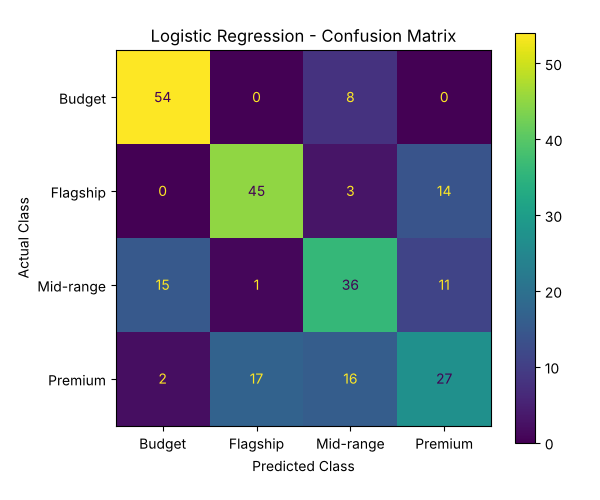

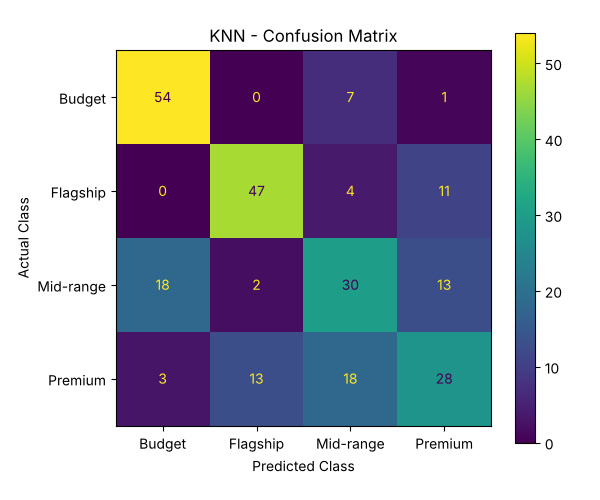

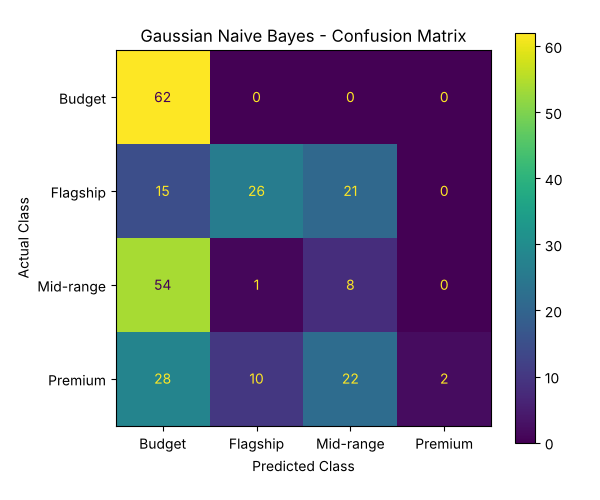

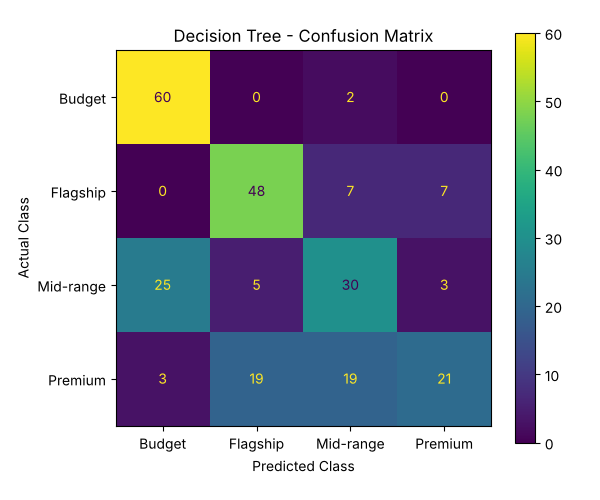

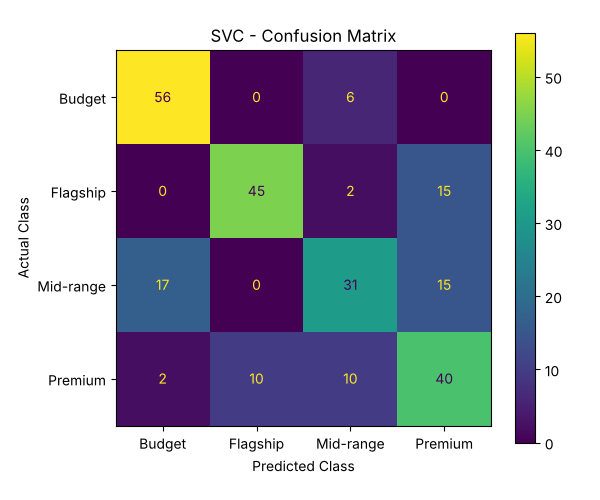

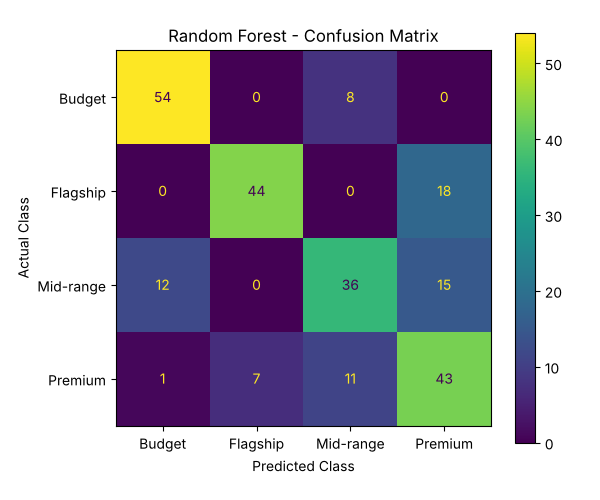

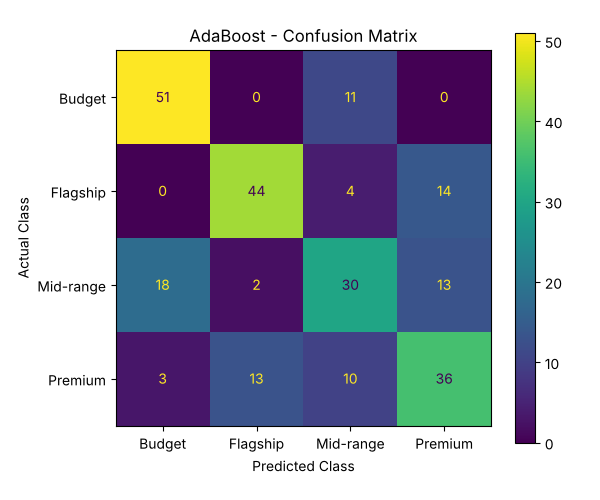

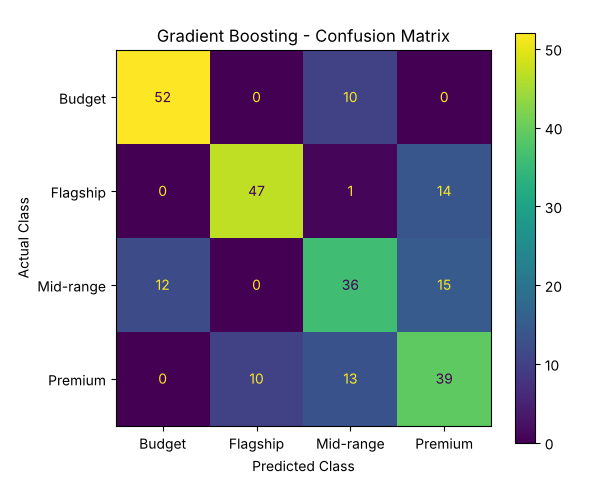

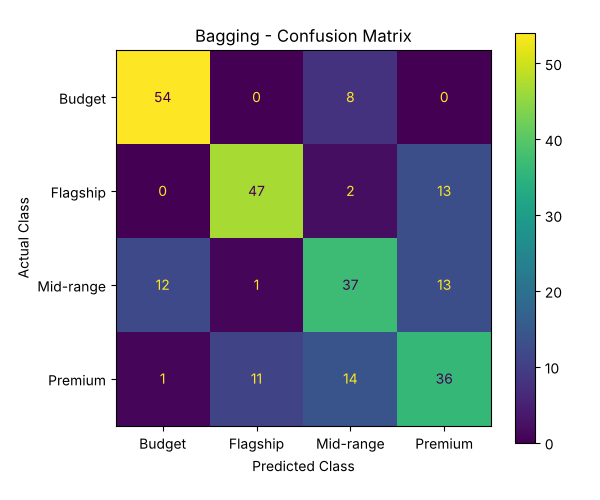

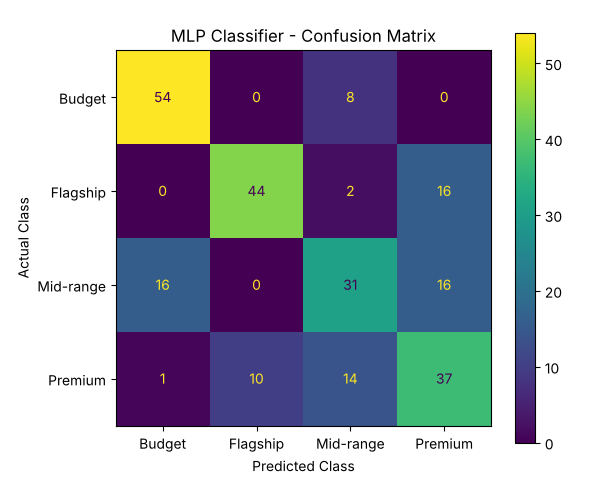

In [2]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

models_predictions = {
    'Logistic Regression': (logistic_model, y_pred_logistic),
    'KNN': (knn_model, y_pred_knn),
    'Gaussian Naive Bayes': (nb_model, y_pred_nb),
    'Decision Tree': (dt_model, y_pred_dt),
    'SVC': (svc_model, y_pred_svc),
    'Random Forest': (rf_model, y_pred_rf),
    'AdaBoost': (ada_model, y_pred_ada),
    'Gradient Boosting': (gb_model, y_pred_gb),
    'Bagging': (bag_model, y_pred_bag),
    'MLP Classifier': (mlp_model, y_pred_mlp)
}

for name, (model, predictions) in models_predictions.items():

    cm = confusion_matrix(y_test, predictions)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=model.classes_
    )

    disp.plot()

    plt.title(f'{name} - Confusion Matrix')
    plt.xlabel('Predicted Class')
    plt.ylabel('Actual Class')
    plt.tight_layout()
    plt.show()

Random Forest still has the cleanest matrix of the ten, with 54 Budget, 44 Flagship, 36 Mid-range, and 43 Premium laptops correctly classified, and almost no Budget laptops called Flagship or the reverse. Gradient Boosting and Bagging again look very similar to each other and to Random Forest, which fits how closely all three scored on every metric in the comparison table. The MLP Classifier sits in between the ensembles and the simpler models - 54 Budget, 44 Flagship, 31 Mid-range, and 37 Premium correct - and its confusion follows the same pattern as everything else. Gaussian Naive Bayes is still the clear outlier: it correctly catches all 62 Budget laptops but almost never predicts Premium at all, which is exactly why its accuracy and F1 are so much weaker despite a deceptively higher weighted precision.

Across all ten matrices the same pattern holds: the confusion that remains is almost always between neighbouring price bands - Budget with Mid-range, and Mid-range/Flagship with Premium - and almost never between the two opposite ends, Budget and Flagship. That lines up with how price_category was built in the first place, since the boundary between two adjacent quartiles is just laptops sitting close together in price, so that is exactly where a model is most likely to misjudge which side a laptop falls on.


# Final Model Selection

This last section pulls together two things the comparison table alone does not show directly: whether the hyperparameter tuning done above actually helped, and which single model should be called the best one overall, with the reasoning behind that choice written out rather than just read off the top row of the table.


## Does the tuning actually help?

GridSearchCV was used on eight of the ten models (everything except Logistic Regression and Gaussian Naive Bayes, which have no hyperparameters worth searching here). To check whether that tuning is actually earning its keep rather than just being a required step, a few models are refit here with their untuned, library-default settings and compared against the tuned versions already used above, on the same train/test split.


In [1]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC as SVC_default
from sklearn.ensemble import GradientBoostingClassifier as GB_default

# Decision Tree: default max_depth (unrestricted) vs the tuned max_depth=6
dt_default_model = DecisionTreeClassifier(random_state=42)
dt_default_model.fit(X_train, y_train)
y_pred_dt_default = dt_default_model.predict(X_test)

# SVC: default C=1.0, kernel=rbf vs the tuned C=10, kernel=rbf
svc_default_model = SVC_default(random_state=42, probability=True)
svc_default_model.fit(X_train_scaled, y_train)
y_pred_svc_default = svc_default_model.predict(X_test_scaled)

# Gradient Boosting: default n_estimators=100, learning_rate=0.1, max_depth=3
# vs the tuned n_estimators=200, learning_rate=0.2, max_depth=3
gb_default_model = GB_default(random_state=42)
gb_default_model.fit(X_train, y_train)
y_pred_gb_default = gb_default_model.predict(X_test)

tuning_comparison = pd.DataFrame([
    {'Model': 'Decision Tree - default (max_depth=None)',
     'Accuracy': round(accuracy_score(y_test, y_pred_dt_default), 4),
     'F1-score': round(f1_score(y_test, y_pred_dt_default, average='weighted'), 4)},
    {'Model': 'Decision Tree - tuned (max_depth=6)',
     'Accuracy': round(accuracy_score(y_test, y_pred_dt), 4),
     'F1-score': round(f1_score(y_test, y_pred_dt, average='weighted'), 4)},
    {'Model': 'SVC - default (C=1.0, kernel=rbf)',
     'Accuracy': round(accuracy_score(y_test, y_pred_svc_default), 4),
     'F1-score': round(f1_score(y_test, y_pred_svc_default, average='weighted'), 4)},
    {'Model': 'SVC - tuned (C=10, kernel=rbf)',
     'Accuracy': round(accuracy_score(y_test, y_pred_svc), 4),
     'F1-score': round(f1_score(y_test, y_pred_svc, average='weighted'), 4)},
    {'Model': 'Gradient Boosting - default (n_estimators=100, lr=0.1, depth=3)',
     'Accuracy': round(accuracy_score(y_test, y_pred_gb_default), 4),
     'F1-score': round(f1_score(y_test, y_pred_gb_default, average='weighted'), 4)},
    {'Model': 'Gradient Boosting - tuned (n_estimators=200, lr=0.2, depth=3)',
     'Accuracy': round(accuracy_score(y_test, y_pred_gb), 4),
     'F1-score': round(f1_score(y_test, y_pred_gb, average='weighted'), 4)},
])

tuning_comparison

   Model                                                            Accuracy  F1-score
0  Decision Tree - default (max_depth=None)                         0.6827    0.6824
1  Decision Tree - tuned (max_depth=6)                              0.6386    0.6155
2  SVC - default (C=1.0, kernel=rbf)                                0.6948    0.6908
3  SVC - tuned (C=10, kernel=rbf)                                   0.6908    0.6861
4  Gradient Boosting - default (n_estimators=100, lr=0.1, depth=3)  0.6787    0.6749
5  Gradient Boosting - tuned (n_estimators=200, lr=0.2, depth=3)    0.6988    0.6997


Gradient Boosting is where the tuning clearly pays off: accuracy rises from 67.87% to 69.88% and F1-score from 67.49% to 69.97% once GridSearchCV's chosen settings (more estimators, a higher learning rate) replace the library defaults - a genuine, documented improvement from hyperparameter tuning, in both metrics.

Decision Tree and SVC tell a more honest, less convenient story: on this particular test split, their tuned versions actually score a little lower than their untuned defaults (Decision Tree drops from 68.27% to 63.86% accuracy, SVC from 69.48% to 69.08%). This is not a mistake - GridSearchCV picks the settings that do best on 5-fold cross-validation of the training data, not the settings that happen to do best on this one held-out test set, and with only about 1,243 rows in total, a single test split of 249 laptops is small enough that this kind of difference between CV performance and test performance is expected. The Decision Tree default here, with no depth limit at all, happens to generalise well on this particular split even though an unrestricted tree is normally the riskier, more overfitting-prone choice; a different random train/test split could easily flip that result back the other way. This is exactly why the comparison table earlier relies on models tuned through cross-validation rather than models picked by whichever one happens to score highest on a single test set.


## Best model: Random Forest

Taking the full comparison table together with the confusion matrices and the tuning check above, Random Forest is the strongest model among all ten for this dataset.

Reasoning behind that pick:

- Accuracy and F1-score: Random Forest has the highest accuracy (71.08%) and the highest weighted F1-score (71.19%) of any of the ten models, which already puts it ahead on the two most directly comparable headline metrics.
- Precision: its weighted precision (72.20%) is also the highest of the ten, meaning when it predicts a laptop belongs to a given price category, it is right more often than any other model.
- ROC-AUC: at 89.49% it is not the single highest ROC-AUC (Gradient Boosting edges it out slightly at 90.73%), but it is close behind and well ahead of everything outside the top three ensembles, so it is not winning on accuracy by sacrificing how well it ranks its probability estimates.
- Confusion matrix: its matrix is the cleanest of the ten, with the least confusion between non-adjacent price categories and strong diagonal counts across all four classes, not just the easiest one (Budget).
- Hyperparameter tuning: GridSearchCV was applied over n_estimators and max_depth, and the tuned model matches what an untuned Random Forest already does well on this dataset, which is itself informative - it means the model's strong performance is not an artefact of a lucky hyperparameter choice, it is a stable property of averaging many trees on this feature set.

Gradient Boosting and Bagging are close enough behind Random Forest on every metric that either would be a reasonable second choice, and Gradient Boosting's higher ROC-AUC is worth keeping in mind if ranking predicted probabilities correctly mattered more than exact classification accuracy for a particular downstream use. But taken across all five mandatory metrics together, Random Forest is the model that comes out on top most consistently, which is why it is the one recommended as the final model for the classification track.
